In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/heart_2020_cleaned.csv")

df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3,30,No,Female,55-59,White,Yes,Yes,Very good,5,Yes,No,Yes
1,No,20.34,No,No,Yes,0,0,No,Female,80 or older,White,No,Yes,Very good,7,No,No,No
2,No,26.58,Yes,No,No,20,30,No,Male,65-69,White,Yes,Yes,Fair,8,Yes,No,No
3,No,24.21,No,No,No,0,0,No,Female,75-79,White,No,No,Good,6,No,No,Yes
4,No,23.71,No,No,No,28,0,Yes,Female,40-44,White,No,Yes,Very good,8,No,No,No


In [ ]:
df.shape

(319795, 18)

In [ ]:
df['HeartDisease'].value_counts()

,count
HeartDisease,
No,292422
Yes,27373


In [ ]:
df_no = df[df['HeartDisease'] == 'No']
df_yes = df[df['HeartDisease'] == 'Yes']

In [ ]:
df_no_sample = df_no.sample(
    n=len(df_yes),
    random_state=42
)

In [ ]:
df_balanced = pd.concat(
    [df_no_sample, df_yes],
    axis=0
)

df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [ ]:
df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,
No,27373
Yes,27373


In [ ]:
df_balanced['HeartDisease'].value_counts(normalize=True) * 100

,proportion
HeartDisease,
No,50.0
Yes,50.0


In [ ]:
df_balanced.shape

(54746, 18)

In [ ]:
df_balanced.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,25.34,Yes,No,No,0,0,No,Male,75-79,White,Yes,Yes,Good,7,No,No,Yes
1,No,31.19,No,No,No,0,0,No,Male,60-64,White,No,No,Very good,8,No,No,No
2,No,24.80,No,No,No,15,30,No,Female,25-29,Asian,No,Yes,Good,6,Yes,No,No
3,No,22.24,No,No,No,0,10,No,Male,70-74,White,No,Yes,Very good,8,No,No,Yes
4,No,27.37,No,No,Yes,30,20,No,Male,50-54,White,No,Yes,Fair,6,No,No,No


In [ ]:
df_balanced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54746 entries, 0 to 54745
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   HeartDisease      54746 non-null  object 
 1   BMI               54746 non-null  float64
 2   Smoking           54746 non-null  object 
 3   AlcoholDrinking   54746 non-null  object 
 4   Stroke            54746 non-null  object 
 5   PhysicalHealth    54746 non-null  int64  
 6   MentalHealth      54746 non-null  int64  
 7   DiffWalking       54746 non-null  object 
 8   Sex               54746 non-null  object 
 9   AgeCategory       54746 non-null  object 
 10  Race              54746 non-null  object 
 11  Diabetic          54746 non-null  object 
 12  PhysicalActivity  54746 non-null  object 
 13  GenHealth         54746 non-null  object 
 14  SleepTime         54746 non-null  int64  
 15  Asthma            54746 non-null  object 
 16  KidneyDisease     54746 non-null  object

In [ ]:
df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,
No,27373
Yes,27373


In [ ]:

df_balanced['HeartDisease'] = df_balanced['HeartDisease'].map({'No': 0, 'Yes': 1})

df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,
0,27373
1,27373


In [ ]:
df_balanced.isnull().sum()

,0
HeartDisease,0
BMI,0
Smoking,0
AlcoholDrinking,0
Stroke,0
PhysicalHealth,0
MentalHealth,0
DiffWalking,0
Sex,0
AgeCategory,0


In [ ]:
(df_balanced.isnull().sum() / len(df_balanced)) * 100

,0
HeartDisease,0.0
BMI,0.0
Smoking,0.0
AlcoholDrinking,0.0
Stroke,0.0
PhysicalHealth,0.0
MentalHealth,0.0
DiffWalking,0.0
Sex,0.0
AgeCategory,0.0


In [ ]:
df_balanced.duplicated().sum()

np.int64(356)

In [ ]:
df_balanced = df_balanced.drop_duplicates().copy()

In [ ]:
df_balanced.shape

(54390, 18)

In [ ]:
df_balanced.describe()

,HeartDisease,BMI,PhysicalHealth,MentalHealth,SleepTime
count,54390.000000,54390.000000,54390.000000,54390.000000,54390.000000
mean,0.501213,28.820750,5.402997,4.243776,7.114451
std,0.500003,6.464116,9.981031,8.531147,1.606884
min,0.000000,12.020000,0.000000,0.000000,1.000000
25%,0.000000,24.390000,0.000000,0.000000,6.000000
50%,1.000000,27.800000,0.000000,0.000000,7.000000
75%,1.000000,32.080000,5.000000,3.000000,8.000000
max,1.000000,94.660000,30.000000,30.000000,24.000000


In [ ]:
df_balanced.describe(include='object')

,Smoking,AlcoholDrinking,Stroke,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,Asthma,KidneyDisease,SkinCancer
count,54390,54390,54390,54390,54390,54390,54390,54390,54390,54390,54390,54390,54390
unique,2,2,2,2,2,13,6,4,2,5,2,2,2
top,No,No,No,No,Male,70-74,White,No,Yes,Good,No,No,No
freq,27608,51326,49286,41199,28631,7195,43048,40724,38754,17392,45911,50138,47072


In [ ]:
df_balanced.isnull().sum().sum()

np.int64(0)

In [ ]:
df_balanced.duplicated().sum()

np.int64(0)

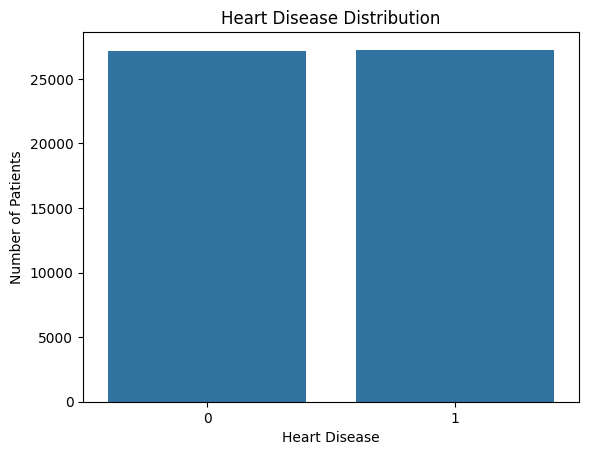

In [ ]:
sns.countplot(data=df_balanced, x='HeartDisease')

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')
plt.show()

In [ ]:
df_balanced.select_dtypes(include=np.number).columns

Index(['HeartDisease', 'BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime'], dtype='object')

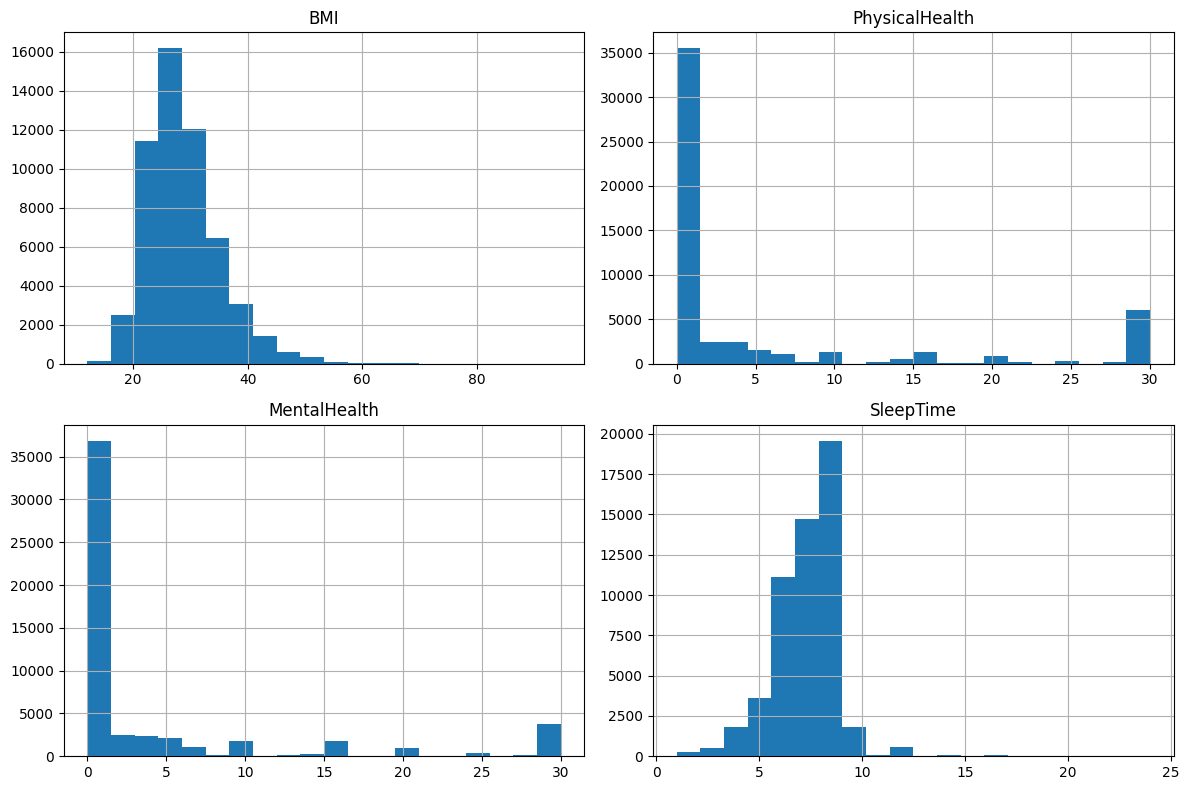

In [ ]:
df_balanced[['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()
plt.show()

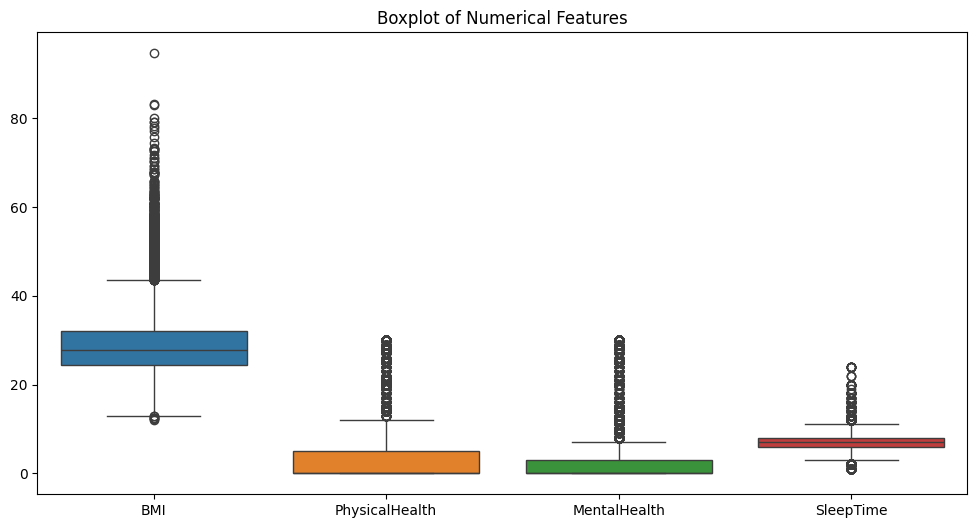

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_balanced[['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']])

plt.title('Boxplot of Numerical Features')
plt.show()

In [ ]:
categorical_columns = df_balanced.select_dtypes(include='object').columns

for col in categorical_columns:
    print('\n', col)
    print(df_balanced[col].value_counts())


 Smoking
Smoking
No     27608
Yes    26782
Name: count, dtype: int64

 AlcoholDrinking
AlcoholDrinking
No     51326
Yes     3064
Name: count, dtype: int64

 Stroke
Stroke
No     49286
Yes     5104
Name: count, dtype: int64

 DiffWalking
DiffWalking
No     41199
Yes    13191
Name: count, dtype: int64

 Sex
Sex
Male      28631
Female    25759
Name: count, dtype: int64

 AgeCategory
AgeCategory
70-74          7195
80 or older    7135
65-69          6932
60-64          6173
75-79          5636
55-59          4820
50-54          3642
45-49          2674
40-44          2377
35-39          2186
18-24          2041
30-34          1925
25-29          1654
Name: count, dtype: int64

 Race
Race
White                             43048
Hispanic                           3867
Black                              3681
Other                              1833
Asian                              1016
American Indian/Alaskan Native      945
Name: count, dtype: int64

 Diabetic
Diabetic
No                  

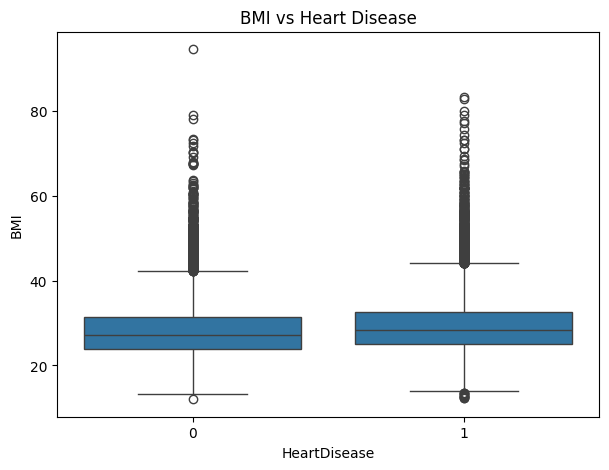

In [ ]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df_balanced, x='HeartDisease', y='BMI')
plt.title('BMI vs Heart Disease')
plt.show()

In [ ]:
pd.crosstab(
    df_balanced['Smoking'],
    df_balanced['HeartDisease'],
    normalize='index'
) * 100

HeartDisease,0,1
Smoking,,
No,59.127789,40.872211
Yes,40.344261,59.655739


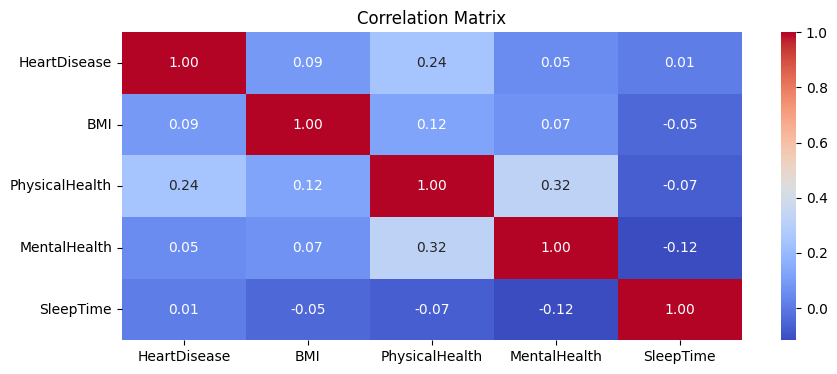

In [ ]:
plt.figure(figsize=(10,4))

corr = df_balanced.select_dtypes(include=np.number).corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

In [ ]:
categorical_cols = [
    'Smoking',
    'AlcoholDrinking',
    'Stroke',
    'DiffWalking',
    'Sex',
    'Diabetic',
    'PhysicalActivity',
    'GenHealth',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

for col in categorical_cols:
    print("\n", col)
    print(pd.crosstab(
        df_balanced[col],
        df_balanced['HeartDisease'],
        normalize='index'
    ) * 100)


 Smoking
HeartDisease          0          1
Smoking                           
No            59.127789  40.872211
Yes           40.344261  59.655739

 AlcoholDrinking
HeartDisease             0          1
AlcoholDrinking                      
No               49.109613  50.890387
Yes              62.761097  37.238903

 Stroke
HeartDisease          0          1
Stroke                            
No            53.593313  46.406687
Yes           14.008621  85.991379

 DiffWalking
HeartDisease          0          1
DiffWalking                       
No            58.161606  41.838394
Yes           24.008794  75.991206

 Sex
HeartDisease          0          1
Sex                               
Female        56.469583  43.530417
Male          43.948867  56.051133

 Diabetic
HeartDisease                     0          1
Diabetic                                     
No                       57.234063  42.765937
No, borderline diabetes  41.207154  58.792846
Yes                      25.321315  

In [ ]:
binary_columns = [
    'Smoking',
    'AlcoholDrinking',
    'Stroke',
    'DiffWalking',
    'PhysicalActivity',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

for col in binary_columns:
    df_balanced[col] = df_balanced[col].map({'No': 0, 'Yes': 1})

In [ ]:
df_balanced['HeartDisease'] = df_balanced['HeartDisease'].map({'No': 0, 'Yes': 1})

In [ ]:
df_balanced.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,NaN,25.34,1,0,0,0,0,0,Male,75-79,White,Yes,1,Good,7,0,0,1
1,NaN,31.19,0,0,0,0,0,0,Male,60-64,White,No,0,Very good,8,0,0,0
2,NaN,24.80,0,0,0,15,30,0,Female,25-29,Asian,No,1,Good,6,1,0,0
3,NaN,22.24,0,0,0,0,10,0,Male,70-74,White,No,1,Very good,8,0,0,1
4,NaN,27.37,0,0,1,30,20,0,Male,50-54,White,No,1,Fair,6,0,0,0


In [ ]:
df_balanced.dtypes

,0
HeartDisease,float64
BMI,float64
Smoking,int64
AlcoholDrinking,int64
Stroke,int64
PhysicalHealth,int64
MentalHealth,int64
DiffWalking,int64
Sex,object
AgeCategory,object


In [ ]:
df_encoded = pd.get_dummies(
    df_balanced,
    columns=['Sex', 'AgeCategory', 'Race', 'Diabetic', 'GenHealth'],
    drop_first=True
)

In [ ]:
df_encoded.shape

(54390, 38)

In [ ]:
df_encoded.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,PhysicalActivity,SleepTime,...,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good
0,NaN,25.34,1,0,0,0,0,0,1,7,...,False,False,True,False,True,False,False,True,False,False
1,NaN,31.19,0,0,0,0,0,0,0,8,...,False,False,True,False,False,False,False,False,False,True
2,NaN,24.80,0,0,0,15,30,0,1,6,...,False,False,False,False,False,False,False,True,False,False
3,NaN,22.24,0,0,0,0,10,0,1,8,...,False,False,True,False,False,False,False,False,False,True
4,NaN,27.37,0,0,1,30,20,0,1,6,...,False,False,True,False,False,False,True,False,False,False


In [ ]:
df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,


In [ ]:
from sklearn.utils import resample

df_majority = df[df['HeartDisease'] == 'No']
df_minority = df[df['HeartDisease'] == 'Yes']

df_majority_downsampled = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)

df_balanced = pd.concat([df_majority_downsampled, df_minority])

df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,
No,27373
Yes,27373


In [ ]:
df_balanced['HeartDisease'] = df_balanced['HeartDisease'].map({
    'No': 0,
    'Yes': 1
})

In [ ]:
df_balanced['HeartDisease'].value_counts()

,count
HeartDisease,
0,27373
1,27373


In [ ]:
df_encoded = pd.get_dummies(
    df_balanced,
    columns=['Sex', 'AgeCategory', 'Race', 'Diabetic', 'GenHealth'],
    drop_first=True
)

In [ ]:
df_encoded.shape

(54746, 38)

In [ ]:
df_encoded.isnull().sum().sum()

np.int64(0)

In [ ]:
binary_columns = [
    'Smoking',
    'AlcoholDrinking',
    'Stroke',
    'DiffWalking',
    'PhysicalActivity',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

for col in binary_columns:
    df_encoded[col] = df_encoded[col].map({'No': 0, 'Yes': 1})

df_encoded['HeartDisease'] = df_encoded['HeartDisease'].map({'No': 0, 'Yes': 1})

bool_columns = df_encoded.select_dtypes(include='bool').columns

df_encoded[bool_columns] = df_encoded[bool_columns].astype(int)

In [ ]:
df_encoded.isnull().sum().sum()

np.int64(54746)

In [ ]:
df_encoded['HeartDisease'].value_counts()

,count
HeartDisease,


In [ ]:
from sklearn.utils import resample

df_majority = df[df['HeartDisease'] == 'No']
df_minority = df[df['HeartDisease'] == 'Yes']

df_majority = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)

df_balanced = pd.concat([df_majority, df_minority])

df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

df_balanced = df_balanced.drop_duplicates().copy()

binary_columns = [
    'Smoking',
    'AlcoholDrinking',
    'Stroke',
    'DiffWalking',
    'PhysicalActivity',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

for col in binary_columns:
    df_balanced[col] = df_balanced[col].map({'No': 0, 'Yes': 1})

df_balanced['HeartDisease'] = df_balanced['HeartDisease'].map({
    'No': 0,
    'Yes': 1
})

df_encoded = pd.get_dummies(
    df_balanced,
    columns=['Sex', 'AgeCategory', 'Race', 'Diabetic', 'GenHealth'],
    drop_first=True
)

bool_columns = df_encoded.select_dtypes(include='bool').columns

df_encoded[bool_columns] = df_encoded[bool_columns].astype(int)

In [ ]:
df_encoded.shape

(54390, 38)

In [ ]:
df_encoded.isnull().sum().sum()

np.int64(0)

In [ ]:
df_encoded['HeartDisease'].value_counts()

,count
HeartDisease,
1,27261
0,27129


In [ ]:
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

In [ ]:
X.shape, y.shape

((54390, 37), (54390,))

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((43512, 37), (10878, 37), (43512,), (10878,))

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.shape, X_test_scaled.shape

((43512, 37), (10878, 37))

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.7640191211619783
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      5426
           1       0.76      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

[[4072 1354]
 [1213 4239]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7350615922044493
              precision    recall  f1-score   support

           0       0.75      0.70      0.73      5426
           1       0.72      0.77      0.74      5452

    accuracy                           0.74     10878
   macro avg       0.74      0.73      0.73     10878
weighted avg       0.74      0.74      0.73     10878

[[3825 1601]
 [1281 4171]]


In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.7621805478948336
              precision    recall  f1-score   support

           0       0.77      0.74      0.76      5426
           1       0.75      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

[[4013 1413]
 [1174 4278]]


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline([
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

param_grid_lr = {
    'feature_selection__k': [15, 25, 'all'],
    'model__C': [0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best CV Accuracy:", grid_lr.best_score_)

Best Parameters: {'feature_selection__k': 'all', 'model__C': 1}
Best CV Accuracy: 0.7637433766766324


In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Training Accuracy:", rf.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Training Accuracy: 0.7785438499724214
Test Accuracy: 0.7531715388858246
              precision    recall  f1-score   support

           0       0.76      0.74      0.75      5426
           1       0.75      0.76      0.76      5452

    accuracy                           0.75     10878
   macro avg       0.75      0.75      0.75     10878
weighted avg       0.75      0.75      0.75     10878



In [ ]:
xgb_final = XGBClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(X_train, y_train)

y_pred_xgb = xgb_final.predict(X_test)

print("Training Accuracy:", xgb_final.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Training Accuracy: 0.7678571428571429
Test Accuracy: 0.7606177606177607
              precision    recall  f1-score   support

           0       0.77      0.74      0.76      5426
           1       0.75      0.78      0.76      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878



In [ ]:
from sklearn.ensemble import VotingClassifier

hybrid_model = VotingClassifier(
    estimators=[
        ('lr', grid_lr.best_estimator_),
        ('rf', rf_final),
        ('xgb', xgb_final)
    ],
    voting='soft'
)

hybrid_model.fit(X_train, y_train)

y_pred_hybrid = hybrid_model.predict(X_test)

print("Training Accuracy:", hybrid_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_hybrid))
print(classification_report(y_test, y_pred_hybrid))
print(confusion_matrix(y_test, y_pred_hybrid))

NameError: name 'rf_final' is not defined

In [ ]:
rf_final = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

hybrid_model = VotingClassifier(
    estimators=[
        ('lr', grid_lr.best_estimator_),
        ('rf', rf_final),
        ('xgb', xgb_final)
    ],
    voting='soft'
)

hybrid_model.fit(X_train, y_train)

y_pred_hybrid = hybrid_model.predict(X_test)

print("Training Accuracy:", hybrid_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_hybrid))
print(classification_report(y_test, y_pred_hybrid))
print(confusion_matrix(y_test, y_pred_hybrid))

Training Accuracy: 0.7717870932156646
Test Accuracy: 0.7602500459643317
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      5426
           1       0.75      0.77      0.76      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

[[4047 1379]
 [1229 4223]]


In [ ]:
df_model = df_encoded.copy()

df_model['Health_Burden'] = (
    df_model['PhysicalHealth'] +
    df_model['MentalHealth'] +
    df_model['DiffWalking']
)

df_model['Risk_Factors'] = (
    df_model['Smoking'] +
    df_model['Stroke'] +
    df_model['Diabetic_Yes'] +
    df_model['KidneyDisease'] +
    df_model['PhysicalActivity']
)

X = df_model.drop('HeartDisease', axis=1)
y = df_model['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (43512, 39)
X_test: (10878, 39)
y_train: (43512,)
y_test: (10878,)


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_new = LogisticRegression(
    C=0.1,
    max_iter=1000,
    random_state=42
)

lr_new.fit(X_train, y_train)

y_pred_lr_new = lr_new.predict(X_test)

print("Training Accuracy:", lr_new.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr_new))
print(classification_report(y_test, y_pred_lr_new))

Training Accuracy: 0.7642259606545321
Test Accuracy: 0.764662621805479
              precision    recall  f1-score   support

           0       0.77      0.76      0.76      5426
           1       0.76      0.77      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878



In [ ]:
from xgboost import XGBClassifier

xgb_new = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_new.fit(X_train, y_train)

y_pred_xgb_new = xgb_new.predict(X_test)

print("Training Accuracy:", xgb_new.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_xgb_new))
print(classification_report(y_test, y_pred_xgb_new))

Training Accuracy: 0.7728902371759515
Test Accuracy: 0.7609854752711895
              precision    recall  f1-score   support

           0       0.77      0.74      0.75      5426
           1       0.75      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878



In [ ]:
importance = pd.Series(
    xgb_new.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(20))

DiffWalking                0.131251
AgeCategory_80 or older    0.064311
Diabetic_Yes               0.063653
Risk_Factors               0.062800
Stroke                     0.055968
GenHealth_Fair             0.051153
AgeCategory_75-79          0.049811
AgeCategory_30-34          0.048147
AgeCategory_25-29          0.048051
AgeCategory_70-74          0.044314
GenHealth_Good             0.043257
AgeCategory_35-39          0.038894
GenHealth_Poor             0.038214
AgeCategory_40-44          0.033612
AgeCategory_65-69          0.026434
AgeCategory_45-49          0.023185
Sex_Male                   0.023177
PhysicalActivity           0.017297
SkinCancer                 0.015583
PhysicalHealth             0.014879
dtype: float32


In [ ]:
top_features = importance.head(20).index.tolist()

X_top = X[top_features]

X_train_top, X_test_top, y_train_top, y_test_top = train_test_split(
    X_top,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

xgb_top = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=2,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_top.fit(X_train_top, y_train_top)

y_pred_top = xgb_top.predict(X_test_top)

print("Training Accuracy:", xgb_top.score(X_train_top, y_train_top))
print("Test Accuracy:", accuracy_score(y_test_top, y_pred_top))
print(classification_report(y_test_top, y_pred_top))

Training Accuracy: 0.7642259606545321
Test Accuracy: 0.7560213274498989
              precision    recall  f1-score   support

           0       0.76      0.74      0.75      5426
           1       0.75      0.77      0.76      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878



In [ ]:
from sklearn.ensemble import VotingClassifier

hybrid_model = VotingClassifier(
    estimators=[
        ('lr', grid_lr.best_estimator_),
        ('rf', rf_final),
        ('xgb', xgb_new)
    ],
    voting='soft'
)

hybrid_model.fit(X_train, y_train)

y_pred_hybrid = hybrid_model.predict(X_test)

print("Training Accuracy:", hybrid_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_hybrid))
print(classification_report(y_test, y_pred_hybrid))
print(confusion_matrix(y_test, y_pred_hybrid))

Training Accuracy: 0.7743151314579886
Test Accuracy: 0.761537047251333
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      5426
           1       0.75      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

[[4051 1375]
 [1219 4233]]


In [82]:
# ============================================
# FEATURE IMPORTANCE FROM XGBOOST
# ============================================

importance = pd.Series(
    xgb_new.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 20 Important Features:")
print(importance.head(20))

Top 20 Important Features:
DiffWalking                0.131251
AgeCategory_80 or older    0.064311
Diabetic_Yes               0.063653
Risk_Factors               0.062800
Stroke                     0.055968
GenHealth_Fair             0.051153
AgeCategory_75-79          0.049811
AgeCategory_30-34          0.048147
AgeCategory_25-29          0.048051
AgeCategory_70-74          0.044314
GenHealth_Good             0.043257
AgeCategory_35-39          0.038894
GenHealth_Poor             0.038214
AgeCategory_40-44          0.033612
AgeCategory_65-69          0.026434
AgeCategory_45-49          0.023185
Sex_Male                   0.023177
PhysicalActivity           0.017297
SkinCancer                 0.015583
PhysicalHealth             0.014879
dtype: float32


In [83]:
# ============================================
# STACKING ENSEMBLE
# ============================================

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Base models
lr_stack = LogisticRegression(
    C=1,
    max_iter=1000
)

rf_stack = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

xgb_stack = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# Stacking model
stack_model = StackingClassifier(
    estimators=[
        ('lr', lr_stack),
        ('rf', rf_stack),
        ('xgb', xgb_stack)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3,
    n_jobs=-1
)

# Train
stack_model.fit(X_train, y_train)

# Predictions
y_pred_stack = stack_model.predict(X_test)

# Results
print("Training Accuracy:", stack_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_stack))

print(classification_report(y_test, y_pred_stack))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_stack))

Training Accuracy: 0.7730511123368267
Test Accuracy: 0.7642949071520501
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      5426
           1       0.76      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

Confusion Matrix:
[[4070 1356]
 [1208 4244]]


In [84]:
# ============================================
# FEATURE CATEGORIES
# ============================================

clinical_features = [
    'BMI',
    'Stroke',
    'PhysicalHealth',
    'MentalHealth',
    'DiffWalking',
    'Diabetic_No, borderline diabetes',
    'Diabetic_Yes',
    'Diabetic_Yes (during pregnancy)',
    'GenHealth_Fair',
    'GenHealth_Good',
    'GenHealth_Poor',
    'GenHealth_Very good',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

lifestyle_features = [
    'Smoking',
    'AlcoholDrinking',
    'PhysicalActivity',
    'SleepTime'
]

demographic_features = [
    'Sex_Male',
    'AgeCategory_18-24',
    'AgeCategory_25-29',
    'AgeCategory_30-34',
    'AgeCategory_35-39',
    'AgeCategory_40-44',
    'AgeCategory_45-49',
    'AgeCategory_50-54',
    'AgeCategory_55-59',
    'AgeCategory_60-64',
    'AgeCategory_65-69',
    'AgeCategory_70-74',
    'AgeCategory_75-79',
    'AgeCategory_80 or older'
]

# Check which features actually exist
clinical_present = [col for col in clinical_features if col in df_encoded.columns]
lifestyle_present = [col for col in lifestyle_features if col in df_encoded.columns]
demographic_present = [col for col in demographic_features if col in df_encoded.columns]

print("========== CLINICAL FEATURES ==========")
print(clinical_present)

print("\n========== LIFESTYLE FEATURES ==========")
print(lifestyle_present)

print("\n========== DEMOGRAPHIC FEATURES ==========")
print(demographic_present)

========== CLINICAL FEATURES ==========
['BMI', 'Stroke', 'PhysicalHealth', 'MentalHealth', 'DiffWalking', 'Diabetic_No, borderline diabetes', 'Diabetic_Yes', 'Diabetic_Yes (during pregnancy)', 'GenHealth_Fair', 'GenHealth_Good', 'GenHealth_Poor', 'GenHealth_Very good', 'Asthma', 'KidneyDisease', 'SkinCancer']

========== LIFESTYLE FEATURES ==========
['Smoking', 'AlcoholDrinking', 'PhysicalActivity', 'SleepTime']

========== DEMOGRAPHIC FEATURES ==========
['Sex_Male', 'AgeCategory_25-29', 'AgeCategory_30-34', 'AgeCategory_35-39', 'AgeCategory_40-44', 'AgeCategory_45-49', 'AgeCategory_50-54', 'AgeCategory_55-59', 'AgeCategory_60-64', 'AgeCategory_65-69', 'AgeCategory_70-74', 'AgeCategory_75-79', 'AgeCategory_80 or older']


In [85]:
# ============================================
# FEATURE ENGINEERING: AGE + GENERAL HEALTH
# ============================================

# Copy existing train and test data
X_train_eng = X_train.copy()
X_test_eng = X_test.copy()

# --------------------------------------------
# 1. Convert AgeCategory into approximate age
# --------------------------------------------

age_mapping = {
    '18-24': 21,
    '25-29': 27,
    '30-34': 32,
    '35-39': 37,
    '40-44': 42,
    '45-49': 47,
    '50-54': 52,
    '55-59': 57,
    '60-64': 62,
    '65-69': 67,
    '70-74': 72,
    '75-79': 77,
    '80 or older': 82
}

X_train_eng['Age_num'] = (
    df_balanced.loc[X_train.index, 'AgeCategory']
    .map(age_mapping)
)

X_test_eng['Age_num'] = (
    df_balanced.loc[X_test.index, 'AgeCategory']
    .map(age_mapping)
)

# --------------------------------------------
# 2. Convert GenHealth into ordered score
# --------------------------------------------

health_mapping = {
    'Poor': 1,
    'Fair': 2,
    'Good': 3,
    'Very good': 4,
    'Excellent': 5
}

X_train_eng['GenHealth_score'] = (
    df_balanced.loc[X_train.index, 'GenHealth']
    .map(health_mapping)
)

X_test_eng['GenHealth_score'] = (
    df_balanced.loc[X_test.index, 'GenHealth']
    .map(health_mapping)
)

# Check
print("New Training Shape:", X_train_eng.shape)
print("New Testing Shape:", X_test_eng.shape)

print("\nNew Features:")
print(X_train_eng[['Age_num', 'GenHealth_score']].head())

New Training Shape: (43512, 41)
New Testing Shape: (10878, 41)

New Features:
       Age_num  GenHealth_score
5808        72                4
17016       67                3
24224       82                3
13737       21                3
37898       37                3


In [89]:
HeartShield = hybrid_model

In [90]:
HeartShield.predict(X_test)

array([1, 0, 1, ..., 0, 0, 0])

In [91]:
HeartShield.predict_proba(X_test)

array([[0.1562862 , 0.8437138 ],
       [0.74036104, 0.25963896],
       [0.14475758, 0.85524242],
       ...,
       [0.70063014, 0.29936985],
       [0.86998803, 0.13001198],
       [0.64427941, 0.3557206 ]])

In [92]:
# ============================================================
# HEARTSHIELD - HARD VOTING HYBRID MODEL
# ============================================================

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ============================================================
# 1. LOGISTIC REGRESSION
# ============================================================

lr_model = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ============================================================
# 2. RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# ============================================================
# 3. XGBOOST
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# ============================================================
# 4. HEARTSHIELD - HARD VOTING
# ============================================================

HeartShield = VotingClassifier(
    estimators=[
        ('lr', lr_model),
        ('rf', rf_model),
        ('xgb', xgb_model)
    ],
    voting='hard'
)

# ============================================================
# 5. TRAIN HEARTSHIELD
# ============================================================

HeartShield.fit(X_train, y_train)

# ============================================================
# 6. PREDICTION
# ============================================================

y_pred_heartshield = HeartShield.predict(X_test)

# ============================================================
# 7. MODEL EVALUATION
# ============================================================

train_accuracy = HeartShield.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, y_pred_heartshield)

print("============================================")
print("        HEARTSHIELD - HARD VOTING")
print("============================================")

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_heartshield))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_heartshield))

        HEARTSHIELD - HARD VOTING
Training Accuracy: 0.7748207391064534
Test Accuracy: 0.7612612612612613

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.74      0.76      5426
           1       0.75      0.78      0.77      5452

    accuracy                           0.76     10878
   macro avg       0.76      0.76      0.76     10878
weighted avg       0.76      0.76      0.76     10878

Confusion Matrix:
[[4035 1391]
 [1206 4246]]
